# Exploração — Preços de Combustíveis (ANP)

Análise exploratória dos dados de preços de combustíveis carregados pelo pipeline `src/extract.py` + `src/load.py`, respondendo as 4 perguntas de negócio do README.

## 1. Setup

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from db import get_engine

engine = get_engine()
sns.set_theme(style='whitegrid')

Matplotlib is building the font cache; this may take a moment.


## 2. Carregamento

In [2]:
fato = pd.read_sql('SELECT * FROM fato_preco', engine)
agg = pd.read_sql('SELECT * FROM agg_preco_mensal_uf', engine)
dim_estado = pd.read_sql('SELECT * FROM dim_estado', engine)

agg = agg.merge(dim_estado, on='uf')
fato.shape, agg.shape

((2607114, 9), (3543, 12))

## 3. Qualidade dos dados

In [3]:
print('Linhas no fato:', len(fato))
print('Nulos por coluna:\n', fato.isna().sum())
print('Range de datas:', fato['data_coleta'].min(), '->', fato['data_coleta'].max())
print('UFs distintas:', fato['uf'].nunique())
print('Categorias:', agg['categoria'].unique())
print('\nOutliers grosseiros em valor_venda:')
fato['valor_venda'].describe()

Linhas no fato: 2607114
Nulos por coluna:
 id             0
data_coleta    0
ano            0
mes            0
uf             0
municipio      0
produto_raw    0
bandeira       0
valor_venda    0
dtype: int64
Range de datas: 2023-01-02 -> 2025-12-31
UFs distintas: 27
Categorias: <ArrowStringArray>
['DIESEL', 'ETANOL', 'GASOLINA', 'GNV']
Length: 4, dtype: str

Outliers grosseiros em valor_venda:


count    2.607114e+06
mean     5.556877e+00
std      9.200636e-01
min      2.390000e+00
25%      4.990000e+00
50%      5.790000e+00
75%      6.190000e+00
max      9.790000e+00
Name: valor_venda, dtype: float64

## 4. Pergunta 1 — Variação de preço por estado/região no tempo

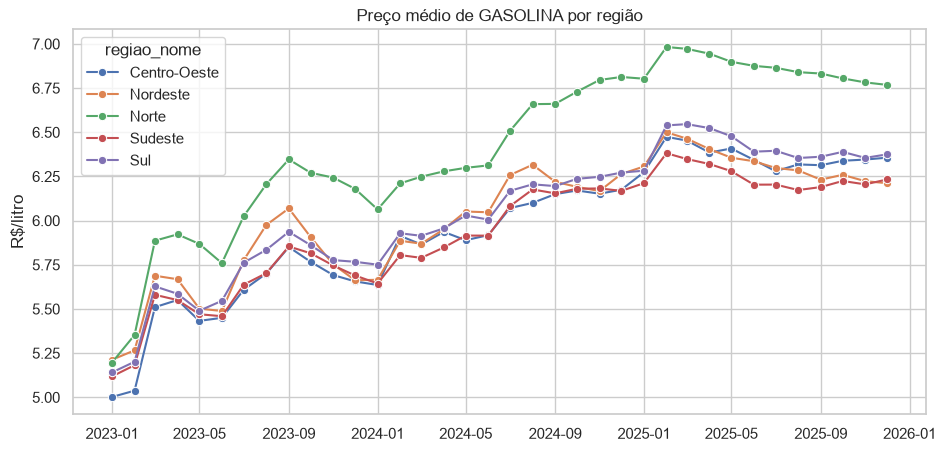

In [4]:
categoria_foco = 'GASOLINA'
sub = agg[agg['categoria'] == categoria_foco].copy()
sub['data'] = pd.to_datetime(dict(year=sub['ano'], month=sub['mes'], day=1))

por_regiao = sub.groupby(['data', 'regiao_nome'])['preco_medio'].mean().reset_index()
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=por_regiao, x='data', y='preco_medio', hue='regiao_nome', marker='o', ax=ax)
ax.set_title(f'Preço médio de {categoria_foco} por região')
ax.set_xlabel('')
ax.set_ylabel('R$/litro')
plt.show()

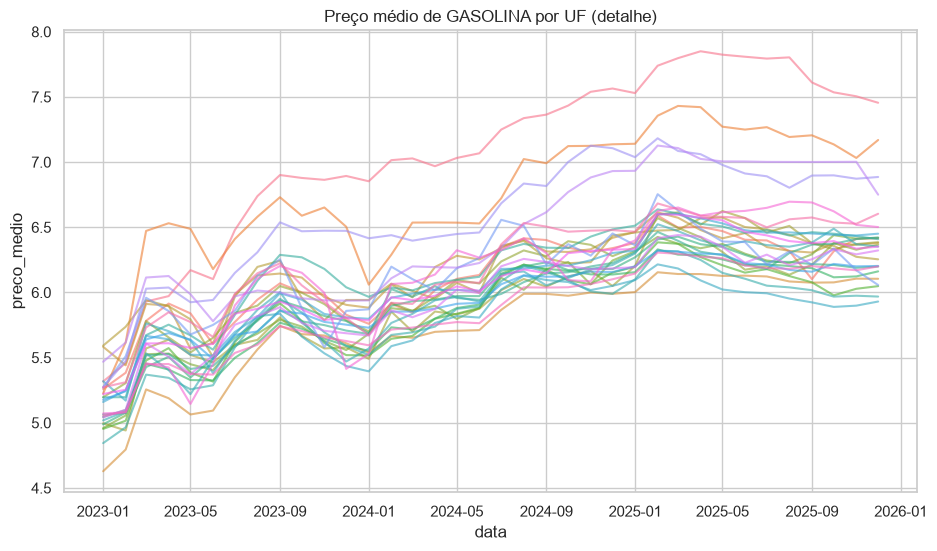

In [5]:
por_uf = sub.groupby(['data', 'uf'])['preco_medio'].mean().reset_index()
fig, ax = plt.subplots(figsize=(11, 6))
sns.lineplot(data=por_uf, x='data', y='preco_medio', hue='uf', legend=False, alpha=0.6, ax=ax)
ax.set_title(f'Preço médio de {categoria_foco} por UF (detalhe)')
plt.show()

## 5. Pergunta 2 — Sazonalidade

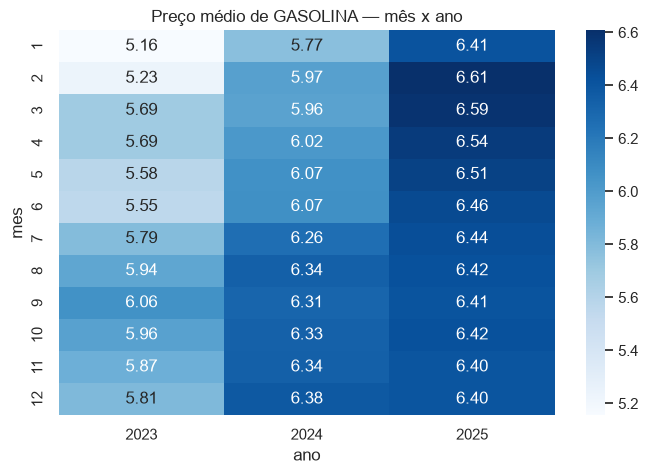

In [6]:
pivot = sub.pivot_table(index='mes', columns='ano', values='preco_medio', aggfunc='mean')
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='Blues', ax=ax)
ax.set_title(f'Preço médio de {categoria_foco} — mês x ano')
plt.show()

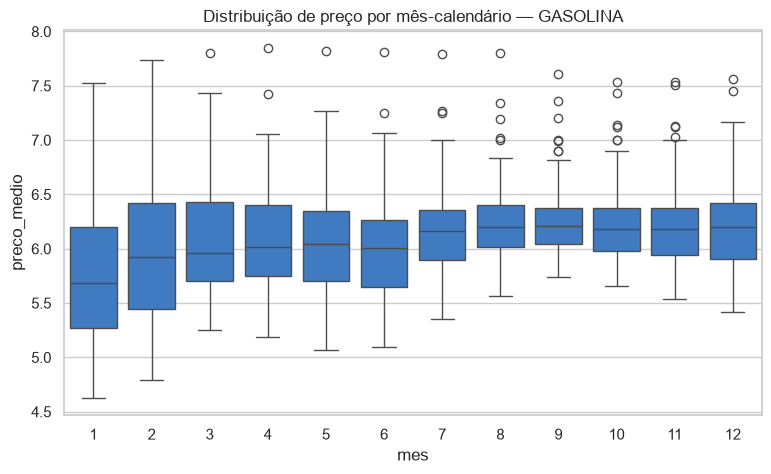

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=sub, x='mes', y='preco_medio', ax=ax, color='#2a78d6')
ax.set_title(f'Distribuição de preço por mês-calendário — {categoria_foco}')
plt.show()

## 6. Pergunta 3 — Volatilidade por estado

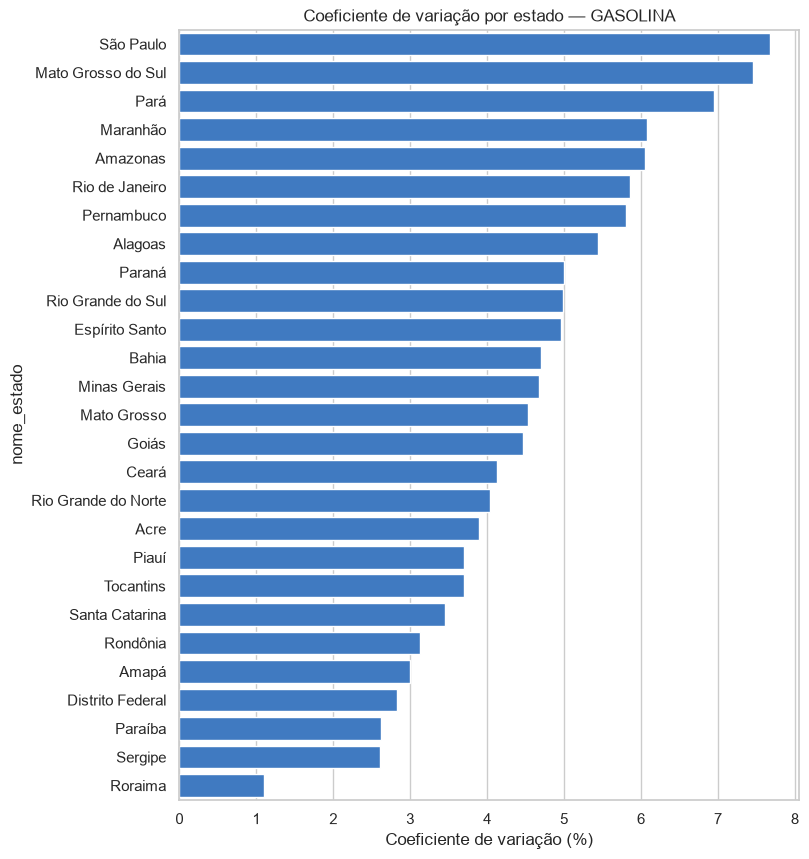

In [8]:
volat = (
    sub.groupby(['uf', 'nome_estado'])
    .agg(preco_medio=('preco_medio', 'mean'), desvio_medio=('desvio_padrao', 'mean'))
    .reset_index()
)
volat['coef_variacao'] = volat['desvio_medio'] / volat['preco_medio'] * 100
volat = volat.sort_values('coef_variacao', ascending=False)

fig, ax = plt.subplots(figsize=(8, 10))
sns.barplot(data=volat, x='coef_variacao', y='nome_estado', color='#2a78d6', ax=ax)
ax.set_title(f'Coeficiente de variação por estado — {categoria_foco}')
ax.set_xlabel('Coeficiente de variação (%)')
plt.show()

## 7. Pergunta 4 — Gap regional

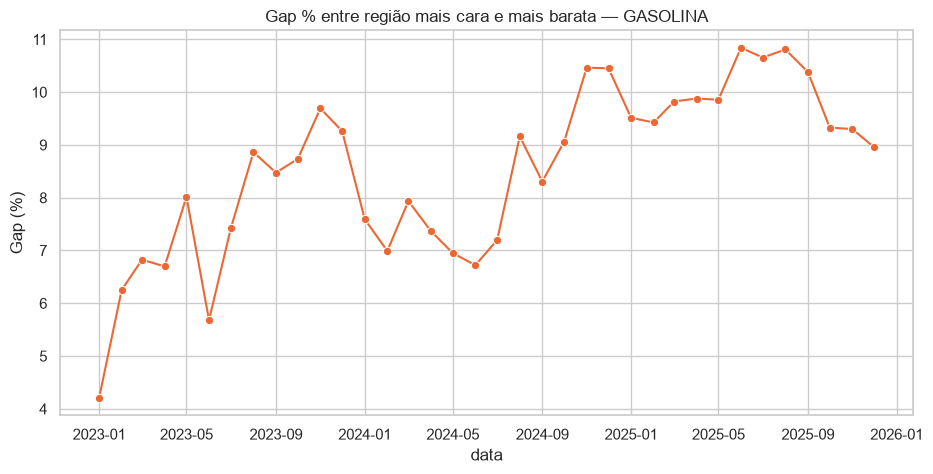

In [9]:
preco_regiao_tempo = sub.groupby(['ano', 'mes', 'regiao_sigla'])['preco_medio'].mean().reset_index()
gap = (
    preco_regiao_tempo.groupby(['ano', 'mes'])['preco_medio']
    .agg(preco_max='max', preco_min='min')
    .reset_index()
)
gap['gap_percentual'] = (gap['preco_max'] - gap['preco_min']) / gap['preco_min'] * 100
gap['data'] = pd.to_datetime(dict(year=gap['ano'], month=gap['mes'], day=1))

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=gap.sort_values('data'), x='data', y='gap_percentual', marker='o', color='#eb6834', ax=ax)
ax.set_title(f'Gap % entre região mais cara e mais barata — {categoria_foco}')
ax.set_ylabel('Gap (%)')
plt.show()

## 8. Conclusões preliminares

(Baseado na carga completa 2023-01 a 2025-12, 2.6M registros, 27 UFs — migrado para a seção "Insights e recomendações" do README.)

- **Pergunta 1 (variação por estado/região):** o preço médio de diesel caiu em todas as regiões entre jan/2023 e dez/2025 (ex.: Nordeste 6,51 -> 6,03 R$/L). O Norte é consistentemente a região mais cara (6,84 -> 6,60), refletindo o custo logístico de levar combustível a áreas remotas.
- **Pergunta 2 (sazonalidade):** há um padrão sazonal claro — jun/jul são os meses mais baratos (~5,81 R$/L) e fevereiro o mais caro (~6,33 R$/L), uma amplitude de ~0,52 R$/L (~8,5%) entre os extremos do ano.
- **Pergunta 3 (volatilidade por estado):** os estados do Norte/Nordeste concentram a maior volatilidade de preço de diesel — AM (8,1% de coeficiente de variação), PA (7,7%), AL (6,9%) — indicando que operações de distribuição nessas regiões precisam de margem de segurança maior no planejamento de custo de combustível.
- **Pergunta 4 (gap regional):** o gap % entre a região mais cara e a mais barata vem aumentando: 9,1% (2023) -> 9,5% (2024) -> 10,5% (2025), ou seja, a disparidade regional de preço está se ampliando, não encolhendo.
